# Hari 1, Sesi 0: Persiapan Google Colab untuk Ekonometrika

**Durasi:** 30 menit

Notebook ini untuk dosen atau pengajar. Isinya: menyiapkan lingkungan kerja,
menyiapkan data, dan mengenali padanan perintah EViews dengan Python.

**Sebelum mulai:** Jalankan sel alamat data di bawah. `URL_DATA` menyimpan alamat folder CSV di GitHub;
`pd.read_csv(...)` membaca tabel sesuai nama CSV pada sel kode berikutnya.
Gunakan koneksi internet dan jalankan sel berurutan dengan **Shift + Enter**.

Cara menjalankan sel: klik selnya, tekan `Shift + Enter`.



**Posisi dalam alur workshop.** Sesi pembuka: menyiapkan alat dan data.
Semua sesi setelah ini memakai pola yang sama, yaitu muat data, estimasi
model, baca output, uji, lalu interpretasi.



**Alur sesi:** kita membaca tabel dan menjalankan model pertama. Mulai dari tabel **Kenali data**, amati grafik, jalankan model, lalu jelaskan hasilnya dengan kata sendiri. Fokus visual sesi ini adalah arti satu baris data, sumbu grafik, dan hasil prediksi.

In [1]:
URL_DATA = "https://raw.githubusercontent.com/akhiyarwaladi/ekonometrika_coding_workshop/main/data/"

print("Alamat data siap. Jalankan sel pembacaan CSV berikutnya.")


Alamat data siap. Jalankan sel pembacaan CSV berikutnya.


## 1. Cek lingkungan

Colab sudah menyediakan pandas, statsmodels, matplotlib, dan seaborn.
Dua paket tambahan yang belum ada dipasang sekali di bawah ini:
`linearmodels` untuk data panel (Sesi 6) dan `arch` untuk GARCH.



In [2]:
%pip install "linearmodels==7.1" "arch==8.0.0" -q


Note: you may need to restart the kernel to use updated packages.


In [3]:
import sys
import pandas as pd
from sklearn.linear_model import LinearRegression
import numpy as np
import statsmodels.api as sm
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette=["#2F5D50", "#C15937", "#D9A441", "#5B8A8F"])
plt.rcParams.update({"figure.dpi": 150, "axes.titleweight": "bold", "font.size": 11})

print("Python", sys.version.split()[0])
print("pandas", pd.__version__)
print("statsmodels", sm.__version__)
print("scikit-learn", sklearn.__version__)



import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 150, "font.size": 11, "axes.labelsize": 11, "axes.titleweight": "bold", "legend.fontsize": 10})


Python 3.13.5
pandas 2.2.3
statsmodels 0.15.0
scikit-learn 1.6.1


## 2. Baca data pertama

`URL_DATA` menyimpan alamat folder CSV di GitHub. Cara membacanya satu baris:
`pd.read_csv(URL_DATA + "regresi_polinom.csv")`.



<!-- kamus_variabel:regresi_polinom.csv -->

### Kenali data: Iklan dan penjualan

**Data:** `data/regresi_polinom.csv`. **Satu baris:** satu tahun pengamatan pada contoh latihan.

Nama singkat di kode berasal dari penggantian nama kolom CSV; isi angkanya tetap sama.

| Kolom CSV | Nama di kode | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|---|
| `Tahun ke-` | `Tahun ke-` | Urutan tahun pengamatan, bukan tahun kalender. | 1, 2, 3, dan seterusnya | Penanda waktu |
| `Biaya Iklan (X)` | `iklan` | Biaya yang dikeluarkan untuk memasang iklan. | Satuan/skala tidak dirinci sumber | X: penjelas |
| `Penjualan (Y)` | `penjualan` | Besarnya penjualan yang ingin dijelaskan oleh biaya iklan. | Satuan/skala tidak dirinci sumber | Y: target |

Jangan menetapkan rupiah, juta rupiah, atau unit barang hanya dari besar angkanya; skala tersebut tidak dicantumkan pada sumber tabel.

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [4]:
data = pd.read_csv(URL_DATA + "regresi_polinom.csv")
print("Ukuran data:", data.shape)
data.head()


Ukuran data: (30, 3)


,Tahun ke-,Biaya Iklan (X),Penjualan (Y)
0,1,5.0,30.1
1,2,6.5,36.2
2,3,8.0,42.5
3,4,9.5,48.8
4,5,11.0,54.1


## 3. Sel pertama yang berguna: satu grafik

Sebelum masuk regresi, lihat datanya dulu. Satu scatter plot bisa
menyelamatkan Anda dari salah spesifikasi yang mahal.



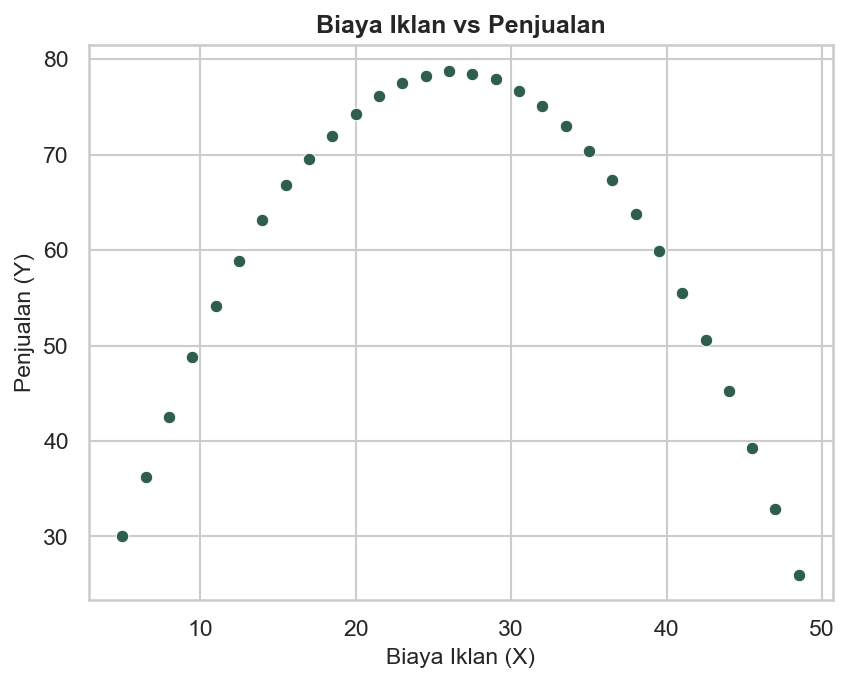

In [5]:
sns.scatterplot(data=data, x="Biaya Iklan (X)", y="Penjualan (Y)")
plt.title("Biaya Iklan vs Penjualan")
plt.show()


**Baca grafik sebelum lanjut:** Satu titik mewakili satu pengamatan. Baca nama dan satuan kedua sumbu, lalu jelaskan arah hubungan serta sebaran titik. Pola visual dipakai untuk memahami model berikutnya, bukan sebagai bukti kausal.

## 4. Membaca rumus model dan angka penting

Simbol `~` dibaca "dijelaskan oleh". Jadi `penjualan ~ iklan` berarti
penjualan dijelaskan oleh iklan. `fit()` menghitung koefisiennya.
Di sini model garis lurus hanya contoh awal; bentuk lengkung dibahas di Sesi 2.



In [6]:
polinom = data.rename(
    columns={"Biaya Iklan (X)": "iklan", "Penjualan (Y)": "penjualan"}
)
sampel_model = polinom[["penjualan", "iklan"]].dropna()
X_model = sampel_model[["iklan"]]
y_model = sampel_model["penjualan"]

model = LinearRegression()
model.fit(X_model, y_model)


LinearRegression()

### Lihat hasil model: Penjualan (skala data)

Di kiri, bandingkan nilai aktual dan prediksi. Di kanan, lihat residual, yaitu aktual dikurangi prediksi. Kedua panel memakai data latihan yang sama dengan model.

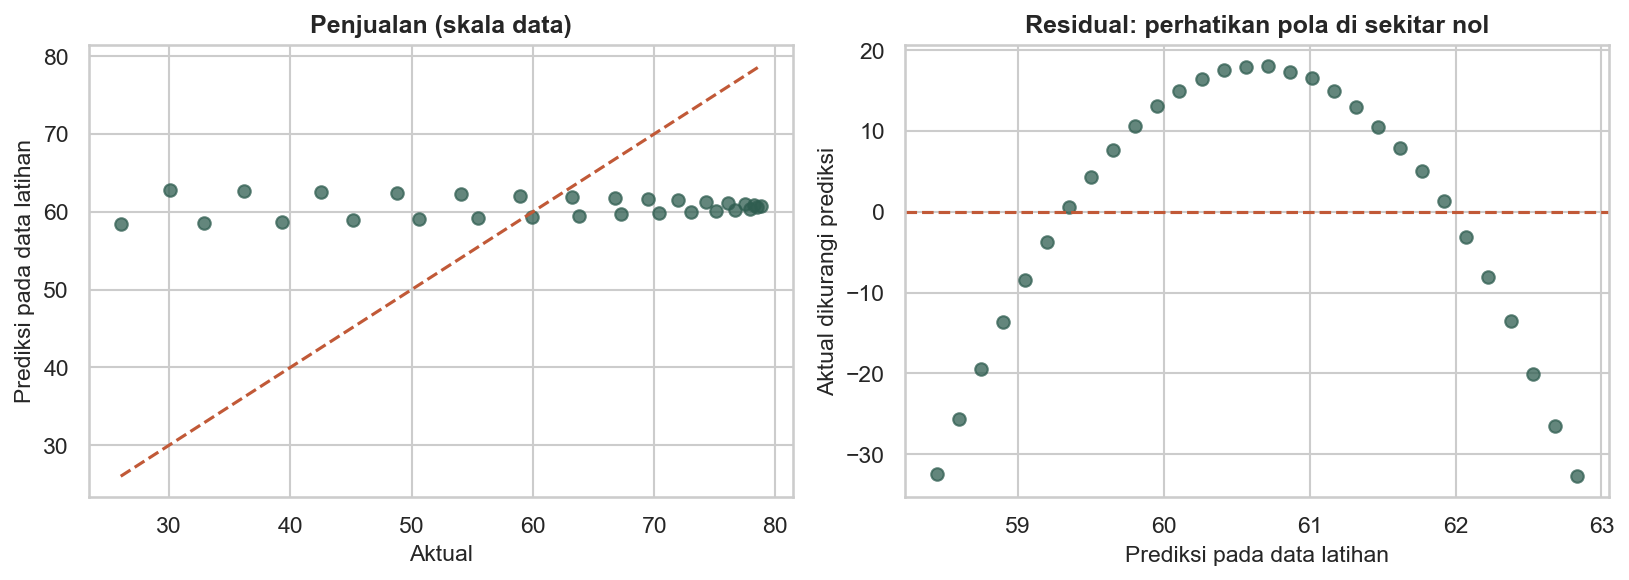

In [7]:
prediksi_visual = model.predict(X_model)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_model, prediksi_visual, color="#2F5D50", alpha=0.75)
batas_visual = [y_model.min(), y_model.max()]
axes[0].plot(batas_visual, batas_visual, "--", color="#C15937")
axes[0].set(xlabel="Aktual", ylabel="Prediksi pada data latihan", title="Penjualan (skala data)")
axes[1].scatter(prediksi_visual, y_model - prediksi_visual, color="#2F5D50", alpha=0.75)
axes[1].axhline(0, color="#C15937", linestyle="--")
axes[1].set(xlabel="Prediksi pada data latihan", ylabel="Aktual dikurangi prediksi", title="Residual: perhatikan pola di sekitar nol")
plt.tight_layout()
plt.show()

**Cara membaca:** titik dekat diagonal mempunyai prediksi yang dekat aktual. Pada panel residual, cari pola melengkung atau lebar sebaran yang berubah. Kecocokan pada data latihan belum mengukur kemampuan memprediksi data baru. Sesudah membaca gambar, hubungkan pola itu dengan angka model dan pertanyaan latihannya. Pada contoh ini residual justru melengkung: hubungan iklan dan penjualan memang belum cocok dengan garis lurus. Ini bahan yang akan kita lanjutkan pada pemilihan bentuk model di Sesi 1–2.

**Pelengkap statistik.** Model dan prediksinya sudah tersedia. Tabel berikut menambahkan standard error dan p-value pada sampel yang sama; gunakan penjelasan setelah tabel untuk memilih angka yang dibaca.

In [8]:
# Pelengkap statistik: standard error dan pengujian pada sampel yang sama.
uji_model = sm.OLS(
    y_model,
    sm.add_constant(X_model, has_constant="add").rename(columns={"const": "Intercept"}),
).fit()


In [9]:
# Baca satu angka setiap baris. Tidak perlu membuat fungsi Python sendiri.
print("Jumlah observasi:", uji_model.nobs)
print("R kuadrat:", model.score(X_model, y_model))
print("R kuadrat terkoreksi:", uji_model.rsquared_adj)
print("p-value uji F:", uji_model.f_pvalue)
print("AIC:", uji_model.aic)


Jumlah observasi: 30.0
R kuadrat: 0.0065772980467725395
R kuadrat terkoreksi: -0.0289020841658425
p-value uji F: 0.670083095460895
AIC: 255.84470425068557


### Coba sendiri (5 menit)

Baca `data/uts_4.csv` ke variabel baru, lalu tampilkan jumlah baris dan
rata-rata kolom `Y_Angka_Harapan_Hidup`. Butuh berapa baris kode?

Tulis di sel di bawah, baru buka jawabannya.



In [10]:
# Tulis kode Anda di sini


<details><summary>Lihat jawaban</summary>

Dua baris: `uts4 = pd.read_csv(URL_DATA + "uts_4.csv")` lalu
`print(len(uts4), uts4["Y_Angka_Harapan_Hidup"].mean())`.
Hasilnya 50 baris dan rata-rata 76,95.

</details>



## 5. Padanan perintah EViews dan Python

Materi kuliah memakai EViews. Tabel ini jembatannya:

| EViews | Python dalam tutorial |
|---|---|
| `ls y c x1 x2` | `LinearRegression().fit(X, y)`; X berisi x1 dan x2 |
| `ls log(y) c log(x)` | Buat kolom log, lalu `LinearRegression().fit(X_log, y_log)` |
| Method **BINARY - Logit** | `LogisticRegression().fit(X, y)` |
| Method **BINARY - Probit** | `smf.probit("y ~ x1", data=df).fit()` |
| Method **ORDERED** | `OrderedModel(...)` dari statsmodels |
| Method **COUNT - Poisson** | `PoissonRegressor(alpha=0).fit(X, y)` |
| Method **ARCH - GARCH(1,1)** | `arch_model(y, vol="Garch", p=1, q=1)` |
| Options > White robust SE | `.fit(cov_type="HC3")` |
| Panel Options: Fixed | `PanelOLS(..., entity_effects=True)` |

Nama kolom output juga beda, artinya sama:

| EViews | statsmodels | Arti |
|---|---|---|
| Coefficient | `coef` | koefisien |
| Std. Error | `std err` | galat baku |
| t-Statistic | `t` | statistik uji |
| Prob. | `pvalue` (ditulis P di output) | p-value |
| R-squared | `rsquared` | proporsi variasi terjelaskan |

### Dua pustaka Python dan porsinya

- **scikit-learn**: model utama, koefisien, prediksi, pembagian data,
  dan evaluasi. Polanya sama: X, y, model, fit, predict.
- **statsmodels**: pelengkap inferensi dan diagnostik, serta model khusus
  seperti probit, ordinal, dan ARIMA. Data panel memakai **linearmodels**,
  sedangkan GARCH memakai **arch**.

OLS tetap metode estimasi `LinearRegression`. Nama `uji_...` membantu
membedakan pelengkap statistik dari model utama scikit-learn.

## 6. Peta materi semester ke notebook ini

| Pertemuan kuliah | Topik | Notebook |
|---|---|---|
| 1-2 | Regresi linear dan bentuk fungsional | `01`, `02` |
| 3-4 | Variabel dummy, multikolinearitas | `03` |
| 5-7 | Heteroskedastisitas, normalitas, autokorelasi | `03` |
| 9-10 | Logit, probit, multinomial, ordinal | `04` |
| 11 | Tobit dan Poisson | `04` |
| 12-13 | Deret waktu, kointegrasi, ECM | `05` |
| 14-15 | GARCH, data panel | `06` |

Dua hari tidak cukup menuntaskan 16 pertemuan. Yang dikejar di workshop
ini: alur kerja lengkap dari data sampai interpretasi, plus contoh kode
untuk setiap topik. Sisanya latihan mandiri.



## Latihan singkat

1. Baca `data/uts_4.csv` (data harapan hidup). Tampilkan 5 baris pertama.
2. Berapa jumlah observasi dan berapa rata-rata `Y_Angka_Harapan_Hidup`?

(Kunci ada di `pengajar/kunci_jawaban/catatan_latihan.md`.)



<!-- kamus_variabel:uts_4.csv -->

### Kenali data: Angka harapan hidup

**Data:** `data/uts_4.csv`. **Satu baris:** satu negara pada contoh latihan.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `Y_Angka_Harapan_Hidup` | Rata-rata lama hidup yang diharapkan menurut indikator pada contoh. | Tahun | Y: target |
| `X1_Pengeluaran_Kesehatan` | Pengeluaran kesehatan per penduduk (per kapita). | Uang per kapita; mata uang/periode tidak dirinci | X: penjelas |
| `X2_Tingkat_Imunisasi` | Persentase anak yang memperoleh imunisasi. | Persen; jenis imunisasi tidak dirinci | X: penjelas |
| `X3_Konsumsi_Kalori` | Rata-rata konsumsi energi makanan per hari. | Kalori harian; rincian satuan energi mengikuti sumber | X: penjelas |

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [11]:
# Tulis jawaban Anda di sini
# uts4 = pd.read_csv(URL_DATA + "uts_4.csv")
# ...


## Praktik pendampingan AI

Setelah contoh regresi berjalan, salin satu sel dan minta AI:

> Saya baru belajar coding. Jelaskan kode ini satu baris setiap kali
> dalam bahasa Indonesia. Sebutkan masukannya, hasil yang disimpan,
> serta bagian yang boleh saya ubah. Gunakan nama yang sama dan
> jangan menambahkan fungsi buatan sendiri atau perulangan.

Cocokkan penjelasannya dengan tabel data dan hasil kode yang dijalankan.
AI tidak perlu menebak koefisien. Ganti satu nilai prediksi, jalankan ulang,
lalu tulis kesimpulan sendiri dengan satuan yang benar. Contoh prompt
untuk membaca output dan memahami error ada di pengajar/referensi/panduan_ai.md.



### Selanjutnya

Selanjutnya: Sesi 1, model regresi pertama.
